## Coding Exercise #0402: Clustering con K-Means

En este notebook aplicamos **K-Means**, un algoritmo de aprendizaje **no supervisado**, al dataset Iris. Aprendizaje no supervisado significa que el modelo solo recibe las variables X (las medidas de las flores) y nunca ve la especie real (Y). Su tarea es encontrar grupos de flores parecidas entre sí.

Como en este caso sí conocemos la especie de cada flor, podemos revisar después si los grupos que encontró K-Means coinciden con las especies reales.

**Contenido:**
1. K-Means con el dataset Iris: carga de datos, entrenamiento, visualización, predicción y conclusiones.
2. K-Means con el dataset Wine: un segundo ejemplo donde vemos la importancia de escalar los datos.
3. Conclusiones generales.

### 1. K-Means clustering con datos reales:

K-Means funciona así:
1. Elige k puntos iniciales como centros de los grupos (centroides).
2. Asigna cada observación al centroide más cercano.
3. Recalcula cada centroide como el promedio de las observaciones de su grupo.
4. Repite los pasos 2 y 3 hasta que los grupos dejan de cambiar.

Hay que indicarle de antemano cuántos grupos buscar (k). Como Iris tiene 3 especies, usaremos k=3.

Importamos las librerías: `numpy` y `pandas` para manejar datos, `matplotlib` y `seaborn` para graficar, y `KMeans` de scikit-learn para el clustering.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')           # Turn off the warnings.
%matplotlib inline

#### 1.1. Cargar el dataset 'Iris' desde Seaborn:

Iris tiene 150 flores de 3 especies (setosa, versicolor y virginica), 50 de cada una, con 4 medidas: largo y ancho del sépalo, y largo y ancho del pétalo.

Separamos los datos en:
- **X:** las 4 medidas, que es lo único que usará K-Means.
- **Y:** la especie real, que guardamos solo para evaluar el resultado al final.

![](https://thumb.wikimedia.org/wikipedia/commons/thumb/c/cb/Flores_de_%C3%8Dris.png/1920px-Flores_de_%C3%8Dris.png?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=thumbnail&_=20230708171909)

In [44]:
df = sns.load_dataset('iris')
X = df.drop(columns=['species'])                        # Only X variables.
Y = df['species']                                       # Only Y variable.
header_X = X.columns                                    # Store the column names of X.
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [69]:
df.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [71]:
df[51:60]

,sepal_length,sepal_width,petal_length,petal_width,species
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
53,5.5,2.3,4.0,1.3,versicolor
54,6.5,2.8,4.6,1.5,versicolor
55,5.7,2.8,4.5,1.3,versicolor
56,6.3,3.3,4.7,1.6,versicolor
57,4.9,2.4,3.3,1.0,versicolor
58,6.6,2.9,4.6,1.3,versicolor
59,5.2,2.7,3.9,1.4,versicolor


In [72]:
df.tail(10)

,sepal_length,sepal_width,petal_length,petal_width,species
140,6.7,3.1,5.6,2.4,virginica
141,6.9,3.1,5.1,2.3,virginica
142,5.8,2.7,5.1,1.9,virginica
143,6.8,3.2,5.9,2.3,virginica
144,6.7,3.3,5.7,2.5,virginica
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


#### 1.2. Aplicar K-Means:

Creamos el modelo con 3 clusters y lo entrenamos solo con X. Fijamos `random_state=123` porque K-Means parte de centroides elegidos al azar; así el resultado es siempre el mismo cada vez que se ejecuta.

Después del entrenamiento, `kmeans.labels_` contiene el número de cluster (0, 1 o 2) asignado a cada flor.

In [45]:
kmeans = KMeans(n_clusters=3, random_state=123)         # kmeans object for 3 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X)                                           # Unsupervised learning => Only X.
res = pd.Series(kmeans.labels_)                         # Cluster labeling result as Series.

**¿Qué especies quedaron en cada cluster?**

K-Means solo entrega números de grupo, no nombres de especies. Para interpretar cada cluster, filtramos Y con las flores que quedaron en él y contamos cuántas hay de cada especie con `value_counts()`.

In [46]:
# Frequency table of the observations labeled as '0'.
# This cluster has the majority 'virginica'.
case0 = Y[res==0]
print(case0.value_counts())

species
virginica     36
versicolor     2
Name: count, dtype: int64


In [47]:
# Frequency table of the observations labeled as '1'.
# This cluster corresponds entirely to 'setosa'.
case1 = Y[res==1]
print(case1.value_counts())

species
setosa    50
Name: count, dtype: int64


In [48]:
# Frequency table of the observations labeled as '2'.
# This cluster has the majority 'versicolor'.
case2 = Y[res==2]
print(case2.value_counts())

species
versicolor    48
virginica     14
Name: count, dtype: int64


Según las tablas anteriores, cada cluster corresponde mayoritariamente a una especie. Guardamos esa correspondencia en una lista: la posición 0 es el nombre del cluster 0, la posición 1 el del cluster 1, y así. Esta lista está escrita a mano; en la sección 2 vemos cómo calcularla automáticamente.

In [49]:
# A list that contains the learned labels.
learnedLabels = ['Virginica', 'Setosa', 'Versicolor']

**Centroides:** cada centroide es el promedio de las 4 medidas de las flores de su cluster, es decir, la "flor típica" de ese grupo. El cluster de setosa tiene pétalos mucho más pequeños (largo 1.46 y ancho 0.25) que los otros dos, lo que explica por qué es el grupo mejor separado.

In [50]:
# Print out the cluster centers (centroids).
np.round(pd.DataFrame(kmeans.cluster_centers_, columns=header_X, index=['Cluster 0', 'Cluster 1', 'Cluster 2']),2)

,sepal_length,sepal_width,petal_length,petal_width
Cluster 0,6.85,3.07,5.74,2.07
Cluster 1,5.01,3.43,1.46,0.25
Cluster 2,5.90,2.75,4.39,1.43


Comprobamos que `case0` es una Serie de pandas, que es lo que necesita `sns.countplot` para graficar.

In [51]:
type(case0)

pandas.core.series.Series

#### 1.3. Visualización:

Graficamos cuántas flores de cada especie quedaron en cada cluster. Un cluster "puro" tendría una sola barra; si aparecen varias barras, ese cluster mezcla especies.

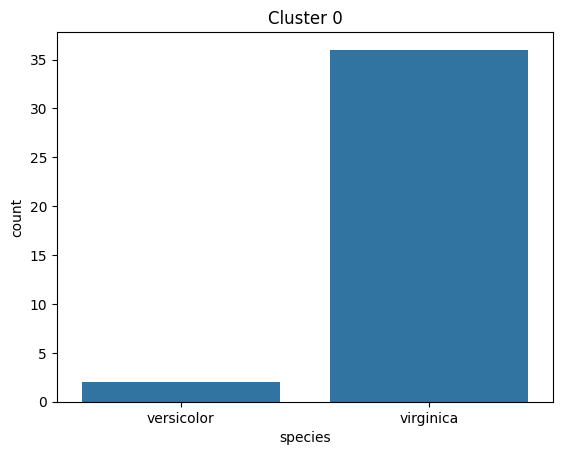

In [52]:
# Visualize the labeling content of the cluster 0.
sns.countplot(x=case0).set_title('Cluster 0')
plt.show()

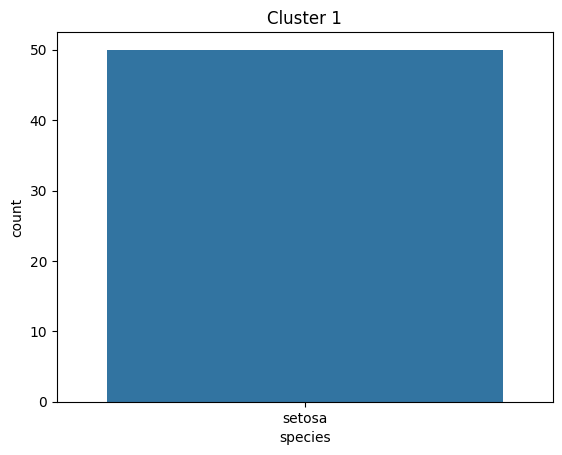

In [53]:
# Visualize the labeling content of the cluster 1.
sns.countplot(x=case1).set_title('Cluster 1')
plt.show()

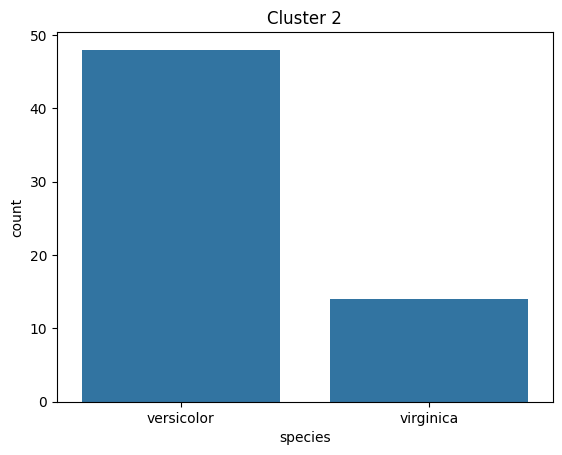

In [54]:
# Visualize the labeling content of the cluster 2.
sns.countplot(x=case2).set_title('Cluster 2')
plt.show()

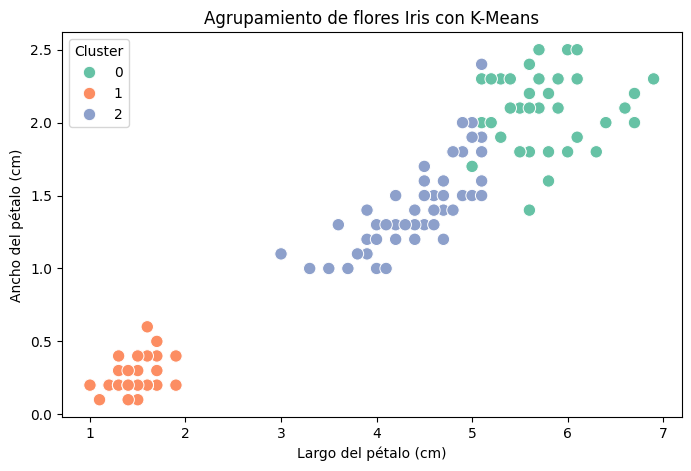

In [55]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=X,
    x="petal_length",
    y="petal_width",
    hue=kmeans.labels_,
    palette="Set2",
    s=80
)

plt.title("Agrupamiento de flores Iris con K-Means")
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.legend(title="Cluster")
plt.show()

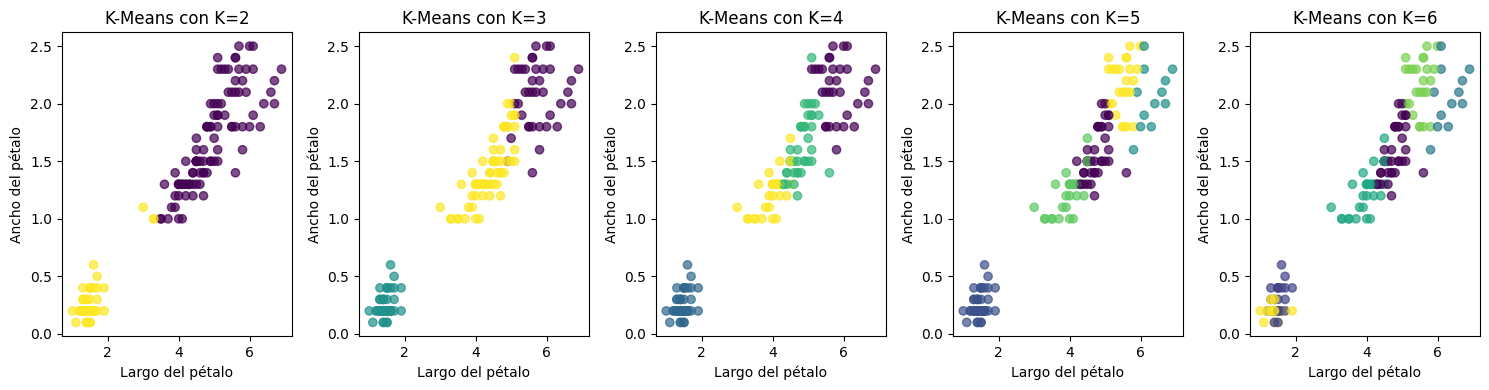

   K  Inercia  Silhouette
0  2  152.348       0.681
1  3   78.851       0.553
2  4   57.228       0.498
3  5   46.446       0.489
4  6   39.066       0.368


In [74]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valores_k = [2, 3, 4, 5, 6]
resultados = []

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, k in enumerate(valores_k):

    modelo = KMeans(
        n_clusters=k,
        random_state=123,
        n_init=10
    )

    clusters = modelo.fit_predict(X)

    # Guardar métricas
    resultados.append({
        "K": k,
        "Inercia": modelo.inertia_,
        "Silhouette": silhouette_score(X, clusters)
    })

    # Visualizar los clusters
    axes[i].scatter(
        X["petal_length"],
        X["petal_width"],
        c=clusters,
        cmap="viridis",
        alpha=0.7
    )

    axes[i].set_title(f"K-Means con K={k}")
    axes[i].set_xlabel("Largo del pétalo")
    axes[i].set_ylabel("Ancho del pétalo")

plt.tight_layout()
plt.show()

# Tabla comparativa
tabla = pd.DataFrame(resultados)
print(tabla.round(3))

#### 1.4. Predicción a partir de lo aprendido:

Una vez entrenado, el modelo puede asignar flores nuevas a un cluster con `kmeans.predict()`: calcula la distancia de la flor a cada centroide y elige el más cercano. Luego usamos `learnedLabels` para traducir ese número de cluster a la especie más probable.

Probamos con tres flores inventadas, una pensada para cada especie.

In [57]:
# For a given observation of X, predict the species from what we have learned.
# Case #1.
X_test = {'sepal_length': [7.0],'sepal_width': [3.0], 'petal_length': [5.0],'petal_width': [1.5]}   # Only X is given.
X_test = pd.DataFrame(X_test)
predCluster = kmeans.predict(X_test)[0]
print(f"Predicted cluster {predCluster} with the most probable label '{learnedLabels[predCluster]}'")

Predicted cluster 0 with the most probable label 'Virginica'


In [58]:
# Case #2.
X_test = {'sepal_length': [4.5],'sepal_width': [3.0] , 'petal_length': [1.0], 'petal_width': [1.0]}   # Only X is given.
X_test = pd.DataFrame(X_test)
predCluster = kmeans.predict(X_test)[0]
print(f"Predicted cluster {predCluster} with the most probable label '{learnedLabels[predCluster]}'")

Predicted cluster 1 with the most probable label 'Setosa'


In [59]:
# Case #3.
X_test = {'sepal_length': [6.0], 'sepal_width': [3.0], 'petal_length': [4.0],'petal_width': [1.0]}   # Only X is given.
X_test = pd.DataFrame(X_test)
predCluster = kmeans.predict(X_test)[0]
print(f"Predicted cluster {predCluster} with the most probable label '{learnedLabels[predCluster]}'")

Predicted cluster 2 with the most probable label 'Versicolor'


#### 1.5. Conclusiones (Iris):

- **Setosa quedó perfectamente separada:** el cluster 1 tiene las 50 setosas y ninguna otra especie. Esto se explica por los centroides: setosa tiene pétalos mucho más pequeños (largo 1.46 cm) que las otras dos especies (4.39 y 5.74 cm).
- **Versicolor y virginica se mezclan:** el cluster 0 tiene 36 virginicas y 2 versicolor, y el cluster 2 tiene 48 versicolor y 14 virginicas. Estas dos especies tienen medidas parecidas y se traslapan, por lo que K-Means no logra separarlas del todo.
- **En total, K-Means agrupó bien 134 de 150 flores (89%)**, sin haber visto nunca la especie real. Esto muestra que las medidas de las flores sí contienen la información necesaria para distinguir las especies.
- **Las predicciones fueron coherentes:** las tres flores de prueba quedaron asignadas a la especie esperada según sus medidas.
- **Importante:** K-Means no "sabe" el nombre de las especies. Los nombres los pusimos nosotros después, comparando los clusters con las etiquetas reales.

### 2. K-Means con otro dataset real: Wine

Para comprobar si lo aprendido funciona con otros datos, repetimos el proceso con el dataset **Wine** de scikit-learn. Contiene 178 vinos de una misma región de Italia, elaborados con 3 variedades de uva distintas (`class_0`, `class_1` y `class_2`). De cada vino hay 13 mediciones químicas, como el alcohol, la acidez, los fenoles, la intensidad del color y la prolina.

La pregunta es la misma que con Iris: **¿puede K-Means agrupar los vinos según su variedad, usando solo su composición química?**

Este dataset tiene una diferencia importante con Iris: sus variables están en escalas muy distintas, y veremos cómo eso afecta al resultado.

![](https://raw.githubusercontent.com/Masterx-AI/Project_Wine_Quality_Investigation/main/wq.jpg)

In [60]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

#### 2.1. Cargar el dataset 'Wine':

Igual que con Iris, separamos las mediciones (X) de la variedad real (Y). Y la usaremos solo al final para evaluar.

In [61]:
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)          # Only X variables.
Y_wine = pd.Series(wine.target).map(dict(enumerate(wine.target_names)))  # Only Y variable (names).
X_wine.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [62]:
# How many wines of each class.
Y_wine.value_counts()

,count
class_1,71
class_0,59
class_2,48


#### 2.2. Aplicar K-Means sin escalar los datos:

Primero aplicamos K-Means directamente, tal como hicimos con Iris.

In [63]:
kmeans_raw = KMeans(n_clusters=3, random_state=123)
kmeans_raw.fit(X_wine)                                   # Unsupervised learning => Only X.
res_raw = pd.Series(kmeans_raw.labels_)
pd.crosstab(res_raw, Y_wine, rownames=['Cluster'], colnames=['Class'])

Class,class_0,class_1,class_2
Cluster,,,
0,0,50,19
1,46,1,0
2,13,20,29


El resultado es bastante peor que con Iris: los clusters 0 y 2 mezclan las tres variedades. En total solo se agrupan bien 125 de 178 vinos (70%).

**¿Por qué?** K-Means agrupa según distancias, y si una variable tiene valores mucho más grandes que las demás, domina el cálculo de la distancia. Veamos el promedio y la desviación estándar de cada variable:

In [64]:
np.round(X_wine.describe().loc[['mean', 'std']].T, 2)

,mean,std
alcohol,13.00,0.81
malic_acid,2.34,1.12
ash,2.37,0.27
alcalinity_of_ash,19.49,3.34
magnesium,99.74,14.28
total_phenols,2.30,0.63
flavanoids,2.03,1.00
nonflavanoid_phenols,0.36,0.12
proanthocyanins,1.59,0.57
color_intensity,5.06,2.32


La variable `proline` tiene valores cercanos a 750 y varía en ±315, mientras que variables como `hue` o `nonflavanoid_phenols` están por debajo de 1. Sin escalar, K-Means prácticamente agrupa solo por prolina e ignora las otras 12 variables.

En Iris no pasaba esto porque las 4 medidas estaban en centímetros y en rangos parecidos.

#### 2.3. Aplicar K-Means con datos escalados:

Usamos `StandardScaler`, que transforma cada variable para que tenga promedio 0 y desviación estándar 1. Así todas las variables pesan lo mismo en el cálculo de distancias.

In [65]:
scaler = StandardScaler()
X_wine_scaled = scaler.fit_transform(X_wine)             # Each variable: mean 0, std 1.

kmeans_wine = KMeans(n_clusters=3, random_state=123)
kmeans_wine.fit(X_wine_scaled)
res_wine = pd.Series(kmeans_wine.labels_)
pd.crosstab(res_wine, Y_wine, rownames=['Cluster'], colnames=['Class'])

Class,class_0,class_1,class_2
Cluster,,,
0,0,64,0
1,59,4,0
2,0,3,48


Ahora cada cluster corresponde casi exclusivamente a una variedad: se agrupan bien 171 de 178 vinos (96%). Solo escalar los datos subió el resultado de 70% a 96%.

Igual que con Iris, asignamos a cada cluster el nombre de la variedad que más se repite en él:

In [66]:
learnedLabels_wine = []
for i in range(3):
    variedad = Y_wine[res_wine==i].value_counts().idxmax()   # Most frequent class in cluster i.
    learnedLabels_wine.append(str(variedad))
learnedLabels_wine

['class_1', 'class_0', 'class_2']

#### 2.4. Visualización:

Graficamos qué variedades quedaron en cada cluster, igual que en la sección 1.3.

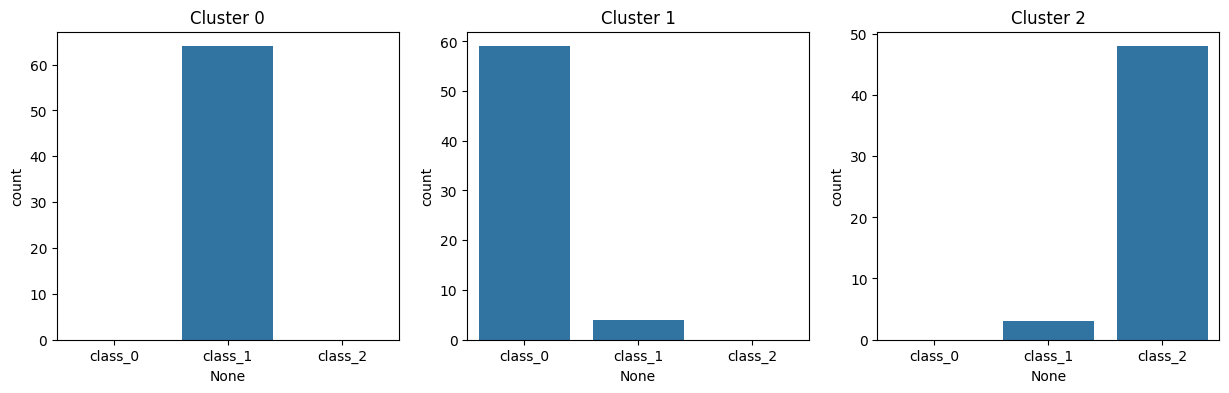

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i in range(3):
    sns.countplot(x=Y_wine[res_wine==i], order=wine.target_names, ax=axes[i])
    axes[i].set_title('Cluster ' + str(i))
plt.show()

#### 2.5. Predicción a partir de lo aprendido:

Tomamos tres vinos del dataset (uno de cada variedad) y le pedimos al modelo que prediga su cluster. Un detalle importante: como el modelo se entrenó con datos escalados, cualquier dato nuevo también debe pasar por el **mismo** `scaler` antes de predecir.

In [68]:
for idx in [10, 100, 170]:
    X_test = X_wine.iloc[[idx]]                          # Only X is given.
    X_test_scaled = scaler.transform(X_test)              # Same scaler used for training.
    predCluster = kmeans_wine.predict(X_test_scaled)[0]
    print(f"Wine {idx}: predicted cluster {predCluster} ('{learnedLabels_wine[predCluster]}'), real class '{Y_wine[idx]}'")

Wine 10: predicted cluster 1 ('class_0'), real class 'class_0'
Wine 100: predicted cluster 0 ('class_1'), real class 'class_1'
Wine 170: predicted cluster 2 ('class_2'), real class 'class_2'


#### 2.6. Conclusiones (Wine):

- **Sin escalar, K-Means funcionó mal (70%)**, porque la prolina, con valores mucho más grandes, dominaba el cálculo de distancias.
- **Con los datos escalados, el resultado subió a 96%**: 171 de 178 vinos quedaron en el cluster de su variedad. Solo 7 vinos de `class_1` quedaron mezclados en otros grupos.
- **La composición química sí distingue las variedades de uva**, y K-Means lo descubrió sin conocer las etiquetas.
- **Al predecir datos nuevos hay que aplicar la misma transformación** que se usó al entrenar; si no, el modelo compararía valores en escalas distintas.

### 3. Conclusiones generales:

1. **K-Means puede encontrar grupos con sentido sin conocer las etiquetas.** En Iris agrupó bien el 89% de las flores y en Wine el 96% de los vinos.
2. **Funciona mejor cuando los grupos están bien separados.** Setosa y las tres variedades de vino quedaron casi perfectas; versicolor y virginica, que se traslapan, se mezclaron.
3. **Escalar los datos es clave** cuando las variables tienen rangos distintos. En Wine marcó la diferencia entre un 70% y un 96%.
4. **Los números de cluster no tienen significado propio.** Los nombres se asignan después, comparando con las etiquetas reales o interpretando los centroides.
5. **Hay que indicar k de antemano.** Aquí era fácil porque sabíamos que había 3 especies y 3 variedades, pero en un problema real sin etiquetas habría que estimarlo, por ejemplo con el método del codo.